# Lab 24.2: Audit a Month of Adverse Action Notices

Run every cell in order; nothing needs to be edited. All data are synthetic and seeded, and reproduce Figure 24.4 (`ch24-reason-audit`) of the chapter.

**The setting.** An invented lender declines applicants whose predicted default risk is above 20 percent. Model v1 (four inputs) decided until day 9; model v2, which adds a debt-to-income ratio, decides from day 10. Each decline notice lists up to four principal reasons, chosen as in Regulation B comment 9(b)(2)-5: the scored factors on which the applicant is furthest from the average of all applicants, in the direction of higher risk. The production log records, for every notice, the applicant's inputs, the model version that decided, the reasons sent and the days between application and notice. Your job is to audit the month.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def fit_logit(X, y, l2=1e-6, iters=50):
    """Newton-Raphson logistic regression with intercept; returns coefficients and standard errors."""
    Z = np.column_stack([np.ones(len(X)), X])
    b = np.zeros(Z.shape[1])
    for _ in range(iters):
        p = 1 / (1 + np.exp(-Z @ b))
        H = Z.T @ (Z * (p * (1 - p))[:, None]) + l2 * np.eye(Z.shape[1])
        step = np.linalg.solve(H, Z.T @ (y - p) - l2 * b)
        b += step
        if np.abs(step).max() < 1e-10:
            break
    p = 1 / (1 + np.exp(-Z @ b))
    H = Z.T @ (Z * (p * (1 - p))[:, None])
    return b, np.sqrt(np.diag(np.linalg.inv(H)))


## 1. The data, the two models and the reason method

In [2]:
FEATURES = ["Credit used (share of limits)", "Missed payments, 24 months",
            "Age of oldest account (years)", "Credit applications, 6 months",
            "Debt-to-income ratio", "Length of residence"]          # last one is NOT scored by any model

def credit_data(n=6000, seed=24):
    rng = np.random.default_rng(seed)
    util = rng.beta(2, 3, n); missed = rng.poisson(0.6, n).clip(0, 8)
    oldest = rng.gamma(4, 2.5, n).clip(0.5, 40); inq = rng.poisson(1.2, n).clip(0, 10)
    dti = rng.beta(2, 5, n)
    X = np.column_stack([util, missed, oldest, inq, dti])
    logit = -3.2 + 2.6 * util + 0.55 * missed - 0.07 * oldest + 0.22 * inq + 2.0 * dti
    y = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(float)
    return X, y

X, y = credit_data()
half = len(X) // 2
b1, _ = fit_logit(X[:half, :4], y[:half]); w1 = np.r_[b1, 0.0]     # v1: older data, no DTI
w2, _ = fit_logit(X[half:], y[half:])                               # v2: newer data, with DTI
mean = X.mean(axis=0)
pd.DataFrame({"v1": w1, "v2": w2}, index=["intercept"] + FEATURES[:5]).round(3)

,v1,v2
intercept,-2.501,-3.129
Credit used (share of limits),2.476,2.465
"Missed payments, 24 months",0.532,0.547
Age of oldest account (years),-0.068,-0.066
"Credit applications, 6 months",0.186,0.225
Debt-to-income ratio,0.000,1.869


In [3]:
def reasons(w, x, k=4):
    c = w[1:] * (x - mean)
    order = [j for j in np.argsort(-c) if c[j] > 0 and w[1 + j] != 0]
    return order[:k]

THR = np.log(0.2 / 0.8)
print("default rate in the data:", round(y.mean(), 3))

default rate in the data: 0.184


*Checkpoint 1:* v1's weights are about 2.48, 0.53, -0.07, 0.19 and 0 for debt-to-income; v2's are about 2.47, 0.55, -0.07, 0.23 and 1.87. The default rate is 0.184.

## 2. The production log for the month

This cell simulates what the lender's systems recorded. In a real audit you would load the log instead. Read the docstring: it says what went wrong, which an auditor would not know in advance.

In [4]:
def notice_log(seed=7):
    """Model v2 went live on day 10; the reason service kept v1's weights until day 21.
    A legacy template added 'Length of residence' to about 4 percent of notices."""
    rng = np.random.default_rng(seed)
    apps = X[rng.choice(len(X), 4000, replace=False)]
    day = rng.integers(1, 31, len(apps))
    rows = []
    for x, d in zip(apps, day):
        w_dec = w1 if d < 10 else w2
        if w_dec[0] + x @ w_dec[1:] <= THR:
            continue                                   # approved: no notice
        w_rsn = w1 if d < 21 else w2
        r = reasons(w_rsn, x)
        if rng.random() < 0.04:
            r = r[:3] + [5]
        lag = int(rng.choice([3, 5, 8, 12, 33], p=[0.4, 0.3, 0.2, 0.08, 0.02]))
        rows.append(dict(day=int(d), model="v1" if d < 10 else "v2", issued=r, x=x, lag=lag))
    return rows

log = notice_log()
print(len(log), "decline notices")
pd.DataFrame([{"day": r["day"], "model": r["model"], "lag_days": r["lag"],
               "reasons_sent": "; ".join(FEATURES[j] for j in r["issued"])} for r in log[:5]])

1395 decline notices


,day,model,lag_days,reasons_sent
0,10,v2,3,"Missed payments, 24 months; Credit application..."
1,14,v2,5,Credit used (share of limits); Age of oldest a...
2,8,v1,3,Credit used (share of limits); Age of oldest a...
3,21,v2,5,"Missed payments, 24 months; Credit application..."
4,17,v2,3,Credit used (share of limits); Age of oldest a...


*Checkpoint 2:* 1,395 decline notices.

## 3. The audit tests

For each notice: (1) re-perform the reasons with the logged model version and compare; (2) check that every reason is a factor the model actually scores (comment 9(b)(2)-4); (3) check that no notice lists more than four reasons (comment 9(b)(2)-1); (4) check the 30-day limit (1002.9(a)(1)).

In [5]:
for r in log:
    w = w1 if r["model"] == "v1" else w2
    r["recomputed"] = reasons(w, r["x"])
    r["match"] = r["issued"] == r["recomputed"]
    r["top1"] = r["issued"][:1] == r["recomputed"][:1]
    r["unscored"] = any(j == 5 or w[1 + j] == 0 for j in r["issued"])
    r["too_many"] = len(r["issued"]) > 4
    r["late"] = r["lag"] > 30

df = pd.DataFrame(log)
findings = pd.Series({
    "notices": len(df),
    "reasons match re-performance": df.match.mean(),
    "top reason matches": df.top1.mean(),
    "cites a factor not scored": df.unscored.mean(),
    "more than four reasons": df.too_many.mean(),
    "sent after 30 days": df.late.mean()}).round(3)
findings

notices                         1395.000
reasons match re-performance       0.736
top reason matches                 0.942
cites a factor not scored          0.036
more than four reasons             0.000
sent after 30 days                 0.017
dtype: float64

*Checkpoint 3:* match 0.736, top reason 0.942, unscored 0.036, more than four reasons 0.0, late 0.017.

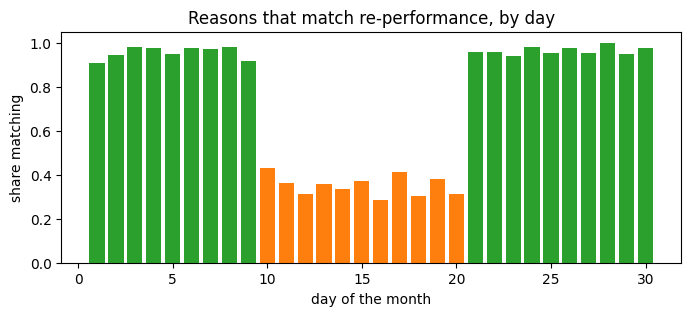

In [6]:
byday = df.groupby("day").match.mean()
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(byday.index, byday.values, color=["tab:orange" if 10 <= d <= 20 else "tab:green" for d in byday.index])
ax.set_xlabel("day of the month"); ax.set_ylabel("share matching")
ax.set_title("Reasons that match re-performance, by day"); plt.show()

## 4. Root cause

The day pattern points to days 10 to 20. Which reason is missing from those notices?

In [7]:
window = df[(df.day >= 10) & (df.day <= 20)]
missing = {}
for _, r in window[~window.match].iterrows():
    for j in set(r.recomputed) - set(r.issued):
        missing[FEATURES[j]] = missing.get(FEATURES[j], 0) + 1
print("mismatches in window:", (~window.match).sum(), "of", len(window))
pd.Series(missing).sort_values(ascending=False)

mismatches in window: 333 of 514


Debt-to-income ratio    320
dtype: int64

*Checkpoint 4:* almost every mismatch in the window omits *Debt-to-income ratio*, the factor v2 added: the reason service was still using v1's weights. Outside the window, the remaining mismatches come from the legacy template's *Length of residence*.

## 5. Your finding memo

Write one page: the finding (what, how many notices, which days), the rule each finding conflicts with, the root cause, the remediation (for example: corrected notices to affected applicants as counsel advises; a release check that the reason service and the decision model share a version identifier; removal of the legacy template), and the control that would have caught it earlier.